## 1. Business Problem

This notebook explores bank customer churn so the project can understand which customers are more likely to leave and how the existing models perform.

## 2. Data Loading and Understanding

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [29]:
data = pd.read_csv('Customer-Churn-Records.csv')
data.head(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1,1,5,DIAMOND,484
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0,0,2,SILVER,206
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1,1,2,DIAMOND,282
8,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0,0,3,GOLD,251
9,10,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0,0,3,GOLD,342


In [30]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

In [31]:
data.shape

(10000, 18)

In [32]:
data.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


## 3. Data Quality Checks

In [33]:
data.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


No null values were detected.

In [34]:
data.duplicated().sum()  # and no duplicated rows

np.int64(0)

In [35]:
data.nunique()

,0
RowNumber,10000
CustomerId,10000
Surname,2932
CreditScore,460
Geography,3
Gender,2
Age,70
Tenure,11
Balance,6382
NumOfProducts,4


## 4. Exploratory Data Analysis

### Target Variable Analysis

<Axes: xlabel='Exited', ylabel='count'>

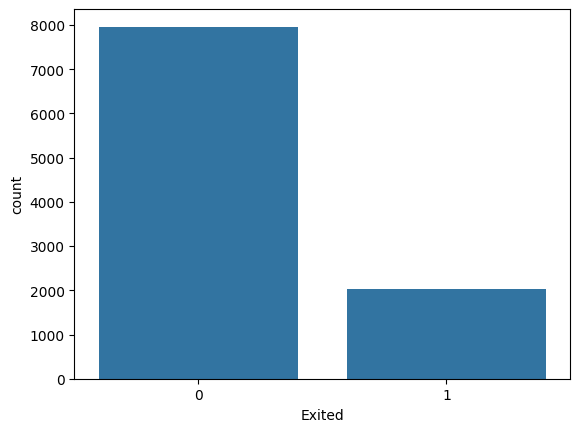

In [36]:
data['Exited'].value_counts()
sns.countplot(x='Exited', data=data) # How many members Exited and not Exited

In [37]:
data['Exited'].value_counts(normalize=True) # It used for checking balance

,proportion
Exited,
0,0.7962
1,0.2038


The target variable is imbalanced, so balancing is handled later in the notebook.

### Univariate Analysis

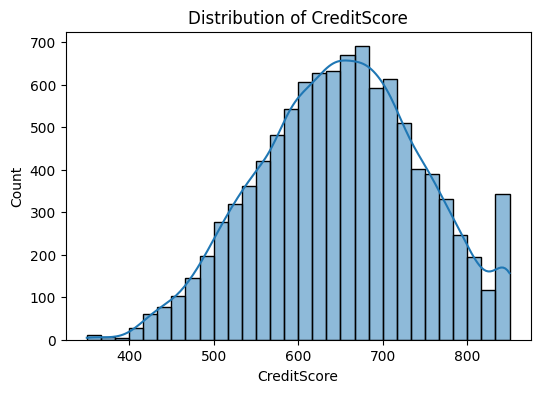

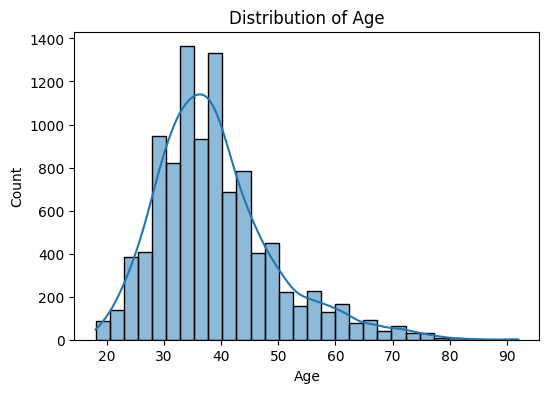

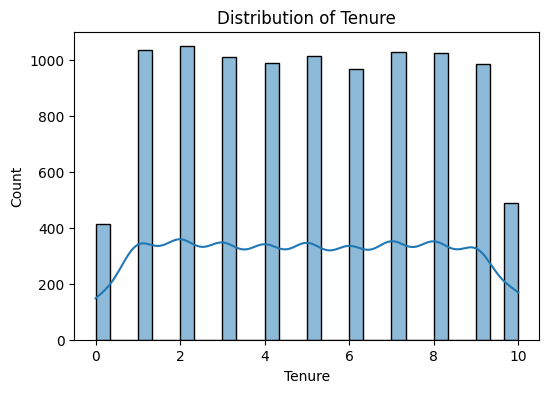

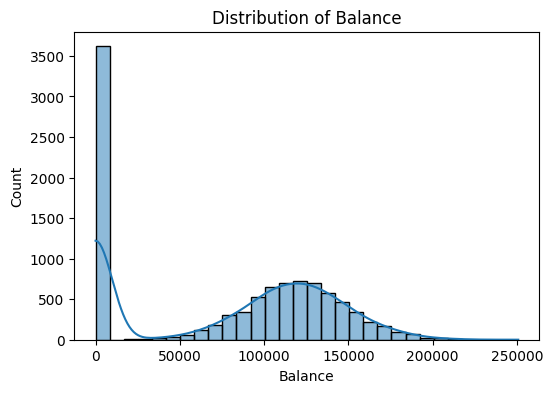

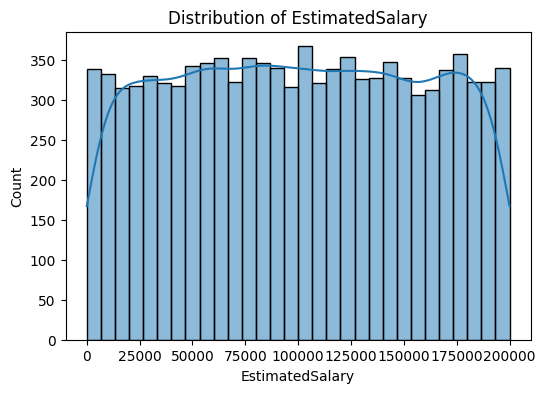

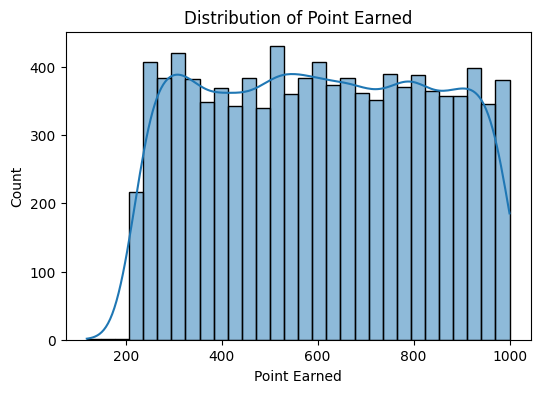

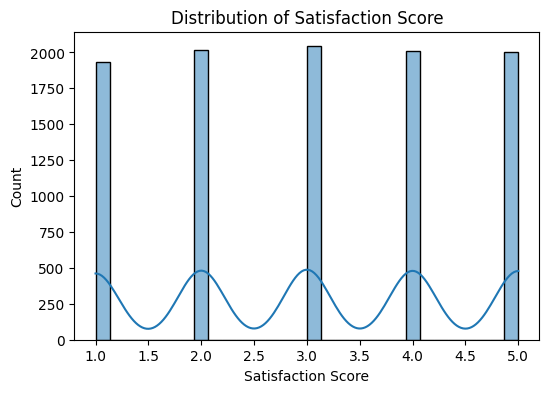

In [38]:
# Numerical Feature Analysis
num_cols = ['CreditScore','Age','Tenure','Balance','EstimatedSalary','Point Earned','Satisfaction Score']
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(data[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.show()
    #Hsitogram plots to analysing Distribution

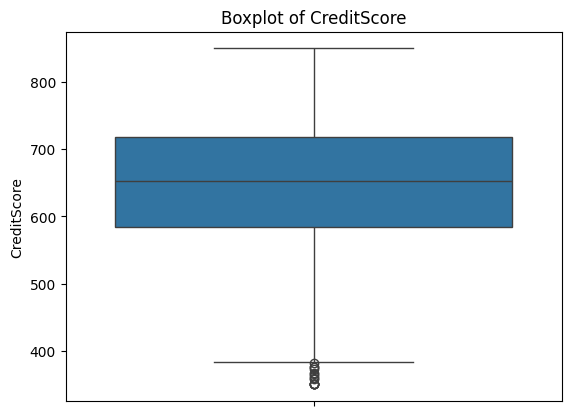

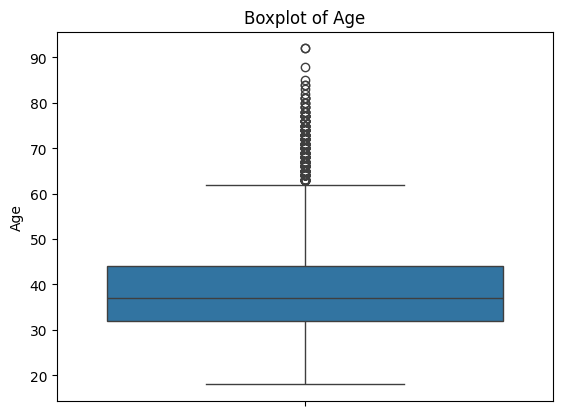

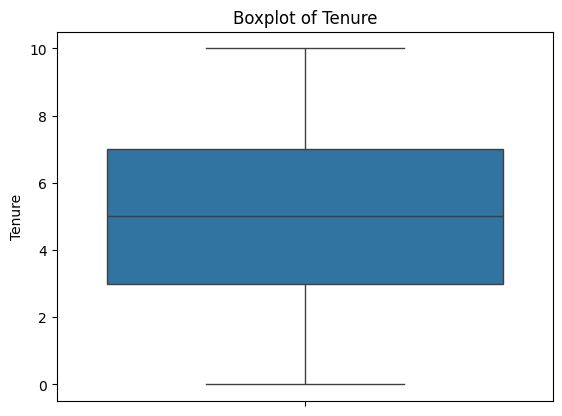

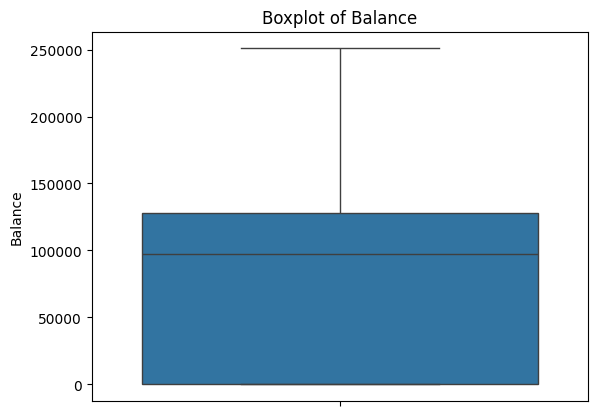

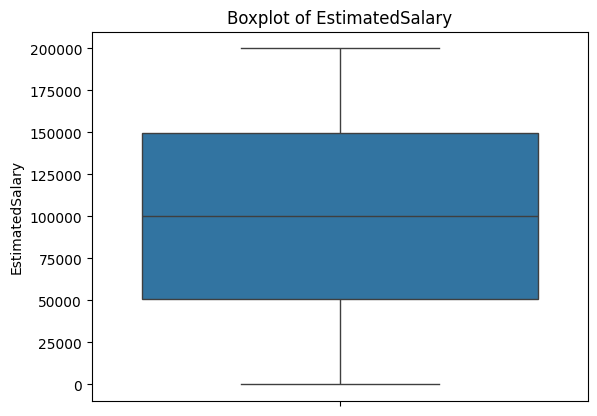

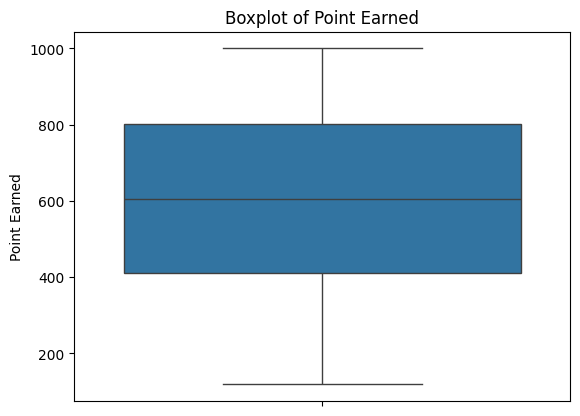

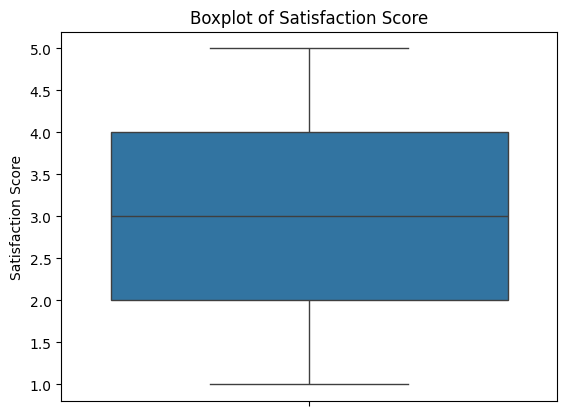

In [39]:
#Boxplot to detects Outliers
for col in num_cols:
    sns.boxplot(data[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

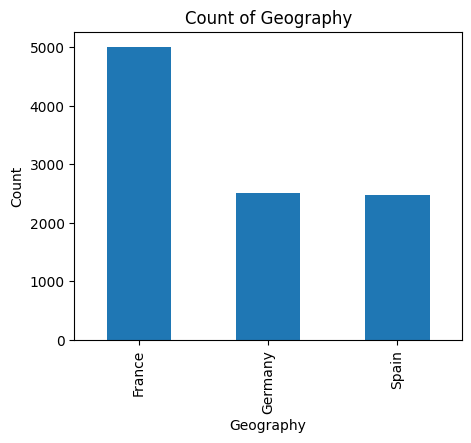

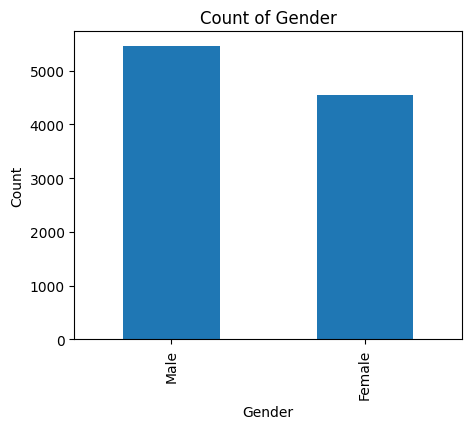

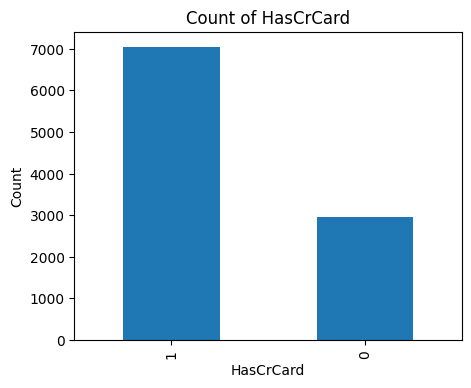

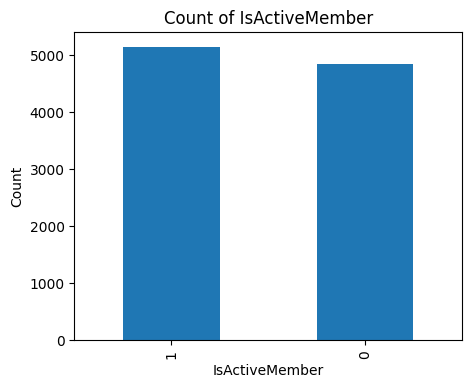

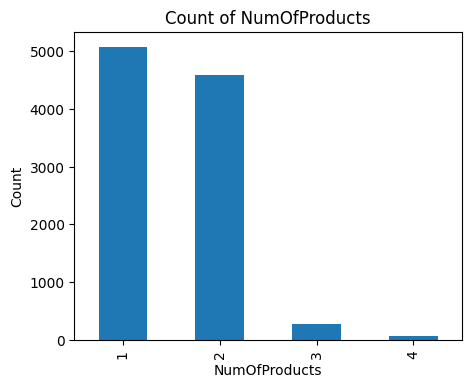

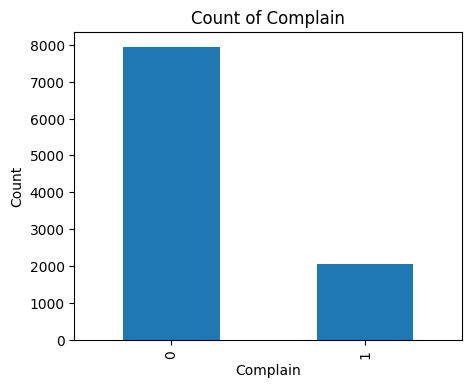

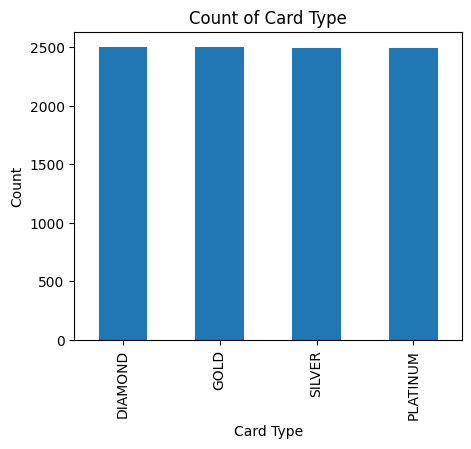

In [40]:
# Categorical Feature Analysis
cat_cols = ['Geography','Gender','HasCrCard','IsActiveMember','NumOfProducts','Complain','Card Type']
for col in cat_cols:
    plt.figure(figsize=(5,4))
    data[col].value_counts().plot(kind='bar')
    plt.title(f"Count of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()
    # Used Bar charts here to Seeing their frequency

### Bivariate Analysis with Churn

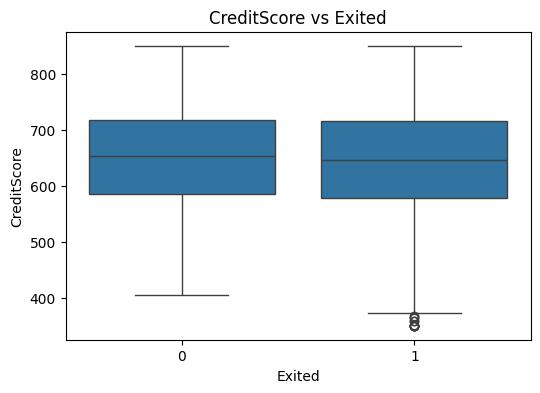

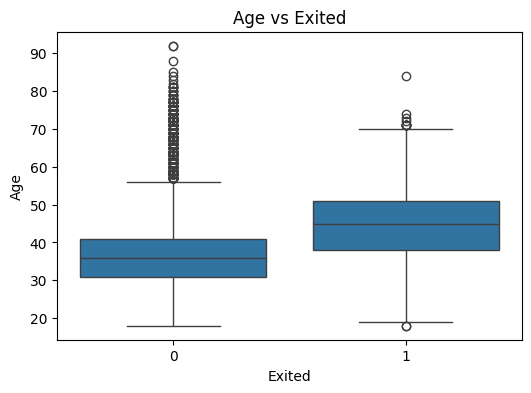

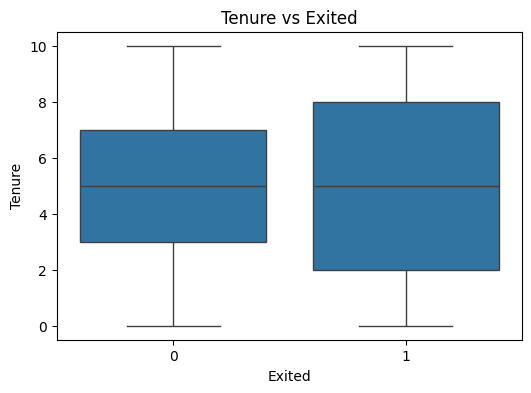

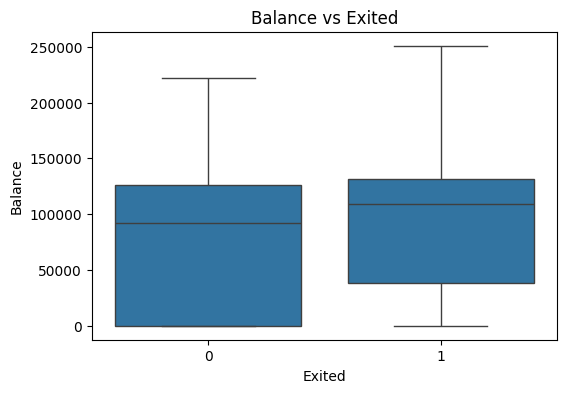

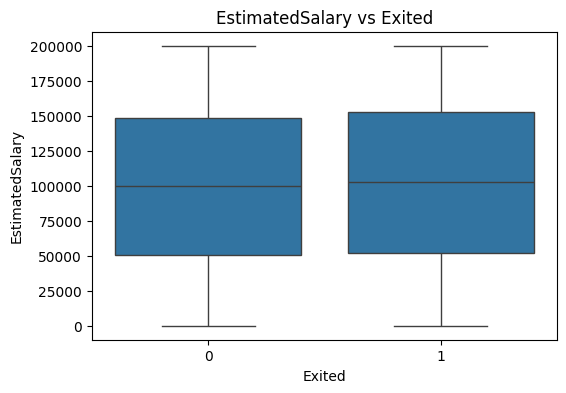

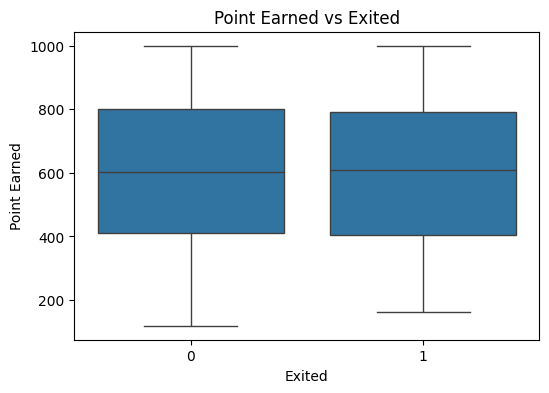

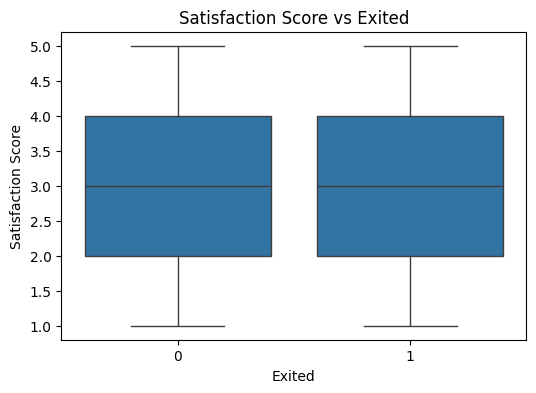

In [41]:
# Numerical Vs Target
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Exited', y=col, data=data)
    plt.title(f'{col} vs Exited')
    plt.show()

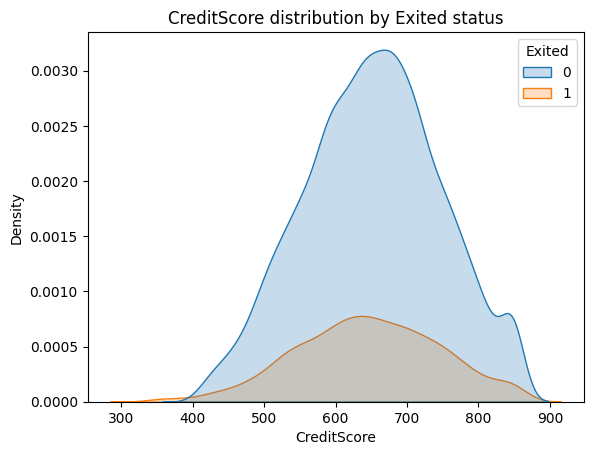

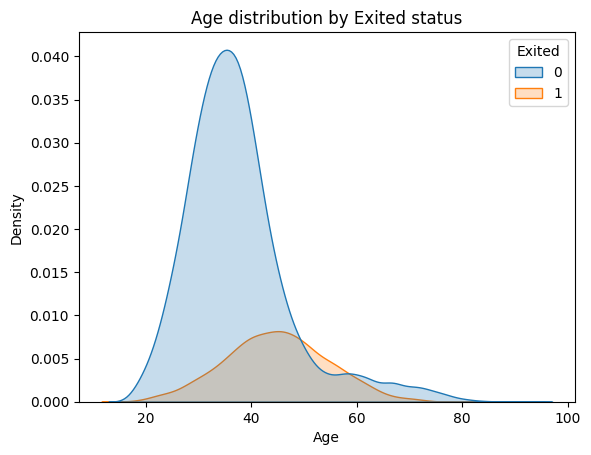

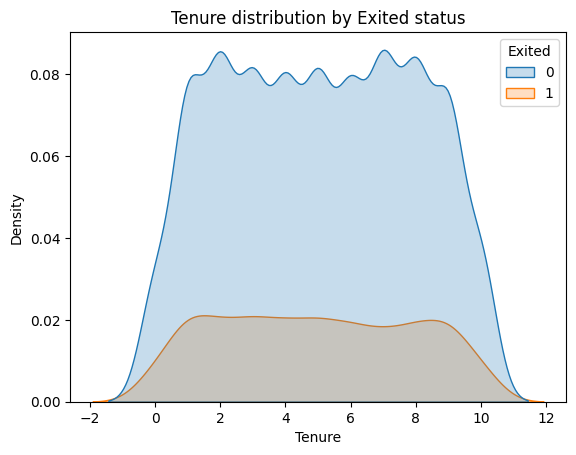

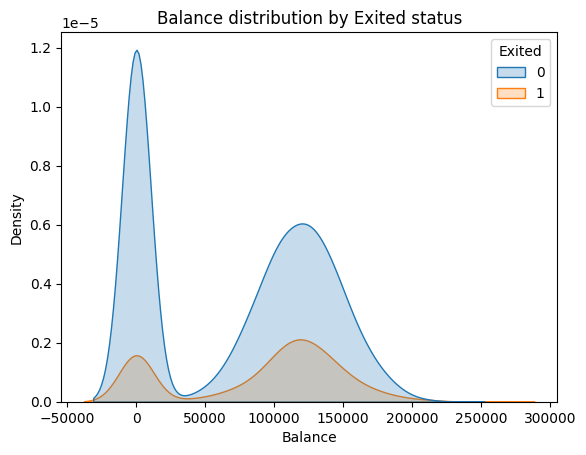

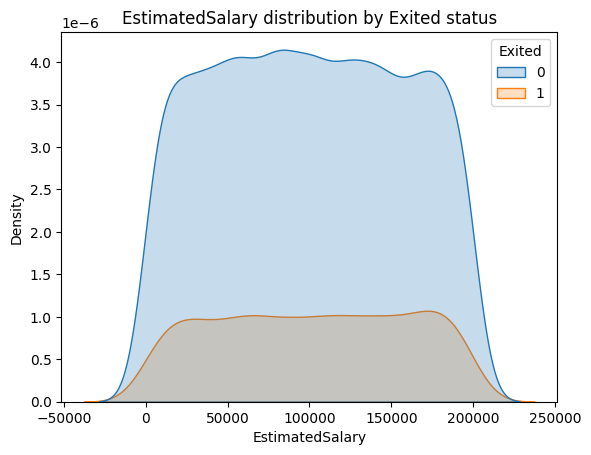

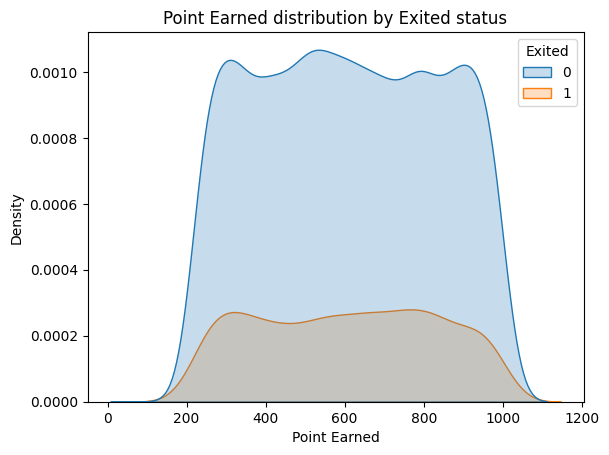

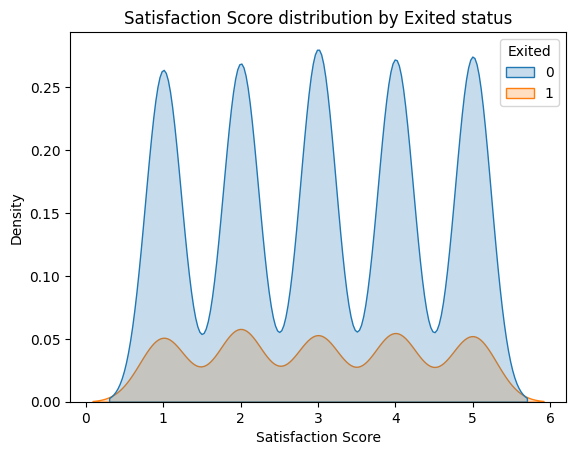

In [42]:
#Visualizing in Distributions
# Comparing mean or distribution of numeric features across churn classes.
for col in num_cols:
    sns.kdeplot(data=data, x=col, hue='Exited', fill=True)
    plt.title(f'{col} distribution by Exited status')
    plt.show()

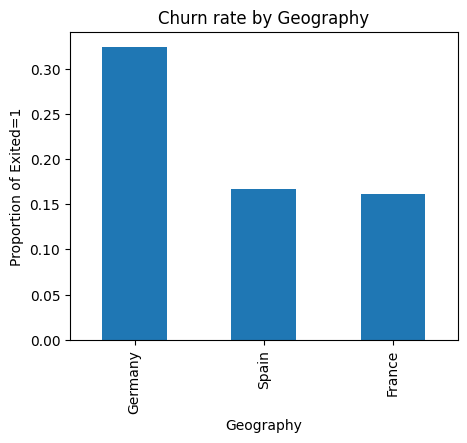

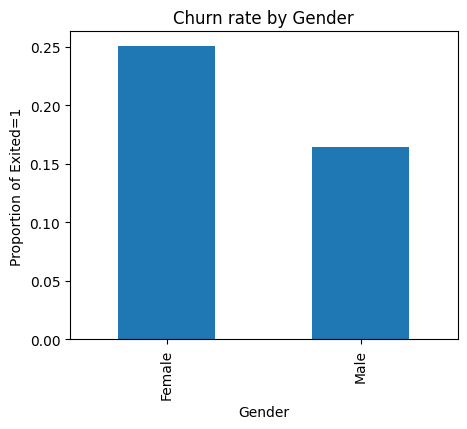

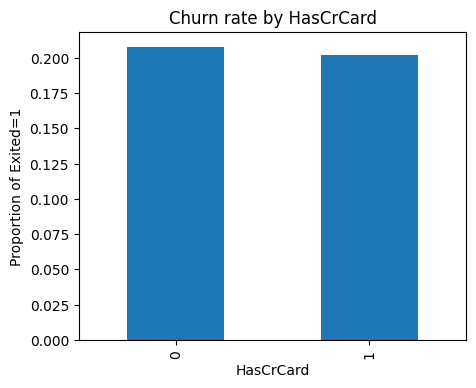

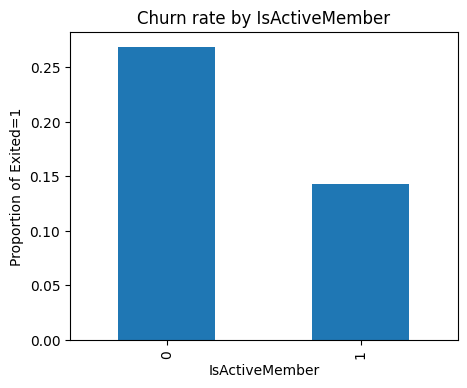

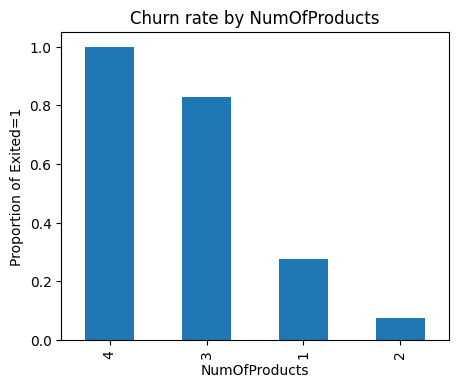

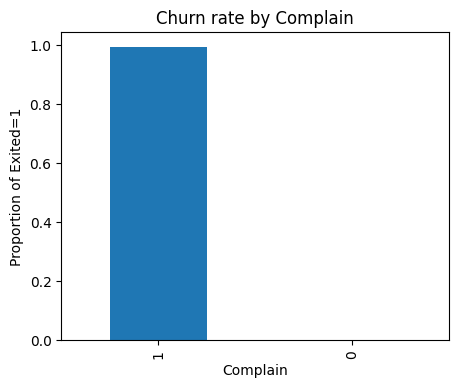

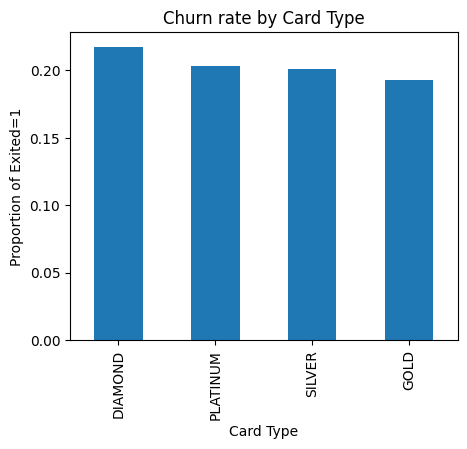

In [43]:
#Categorical Vs Target
# Comparing churn rate across each category.
for col in cat_cols:
    churn_rate = data.groupby(col)['Exited'].mean().sort_values(ascending=False)
    churn_rate.plot(kind='bar', figsize=(5,4))
    plt.title(f'Churn rate by {col}')
    plt.ylabel('Proportion of Exited=1')
    plt.show()

### Correlation and Relationship Analysis

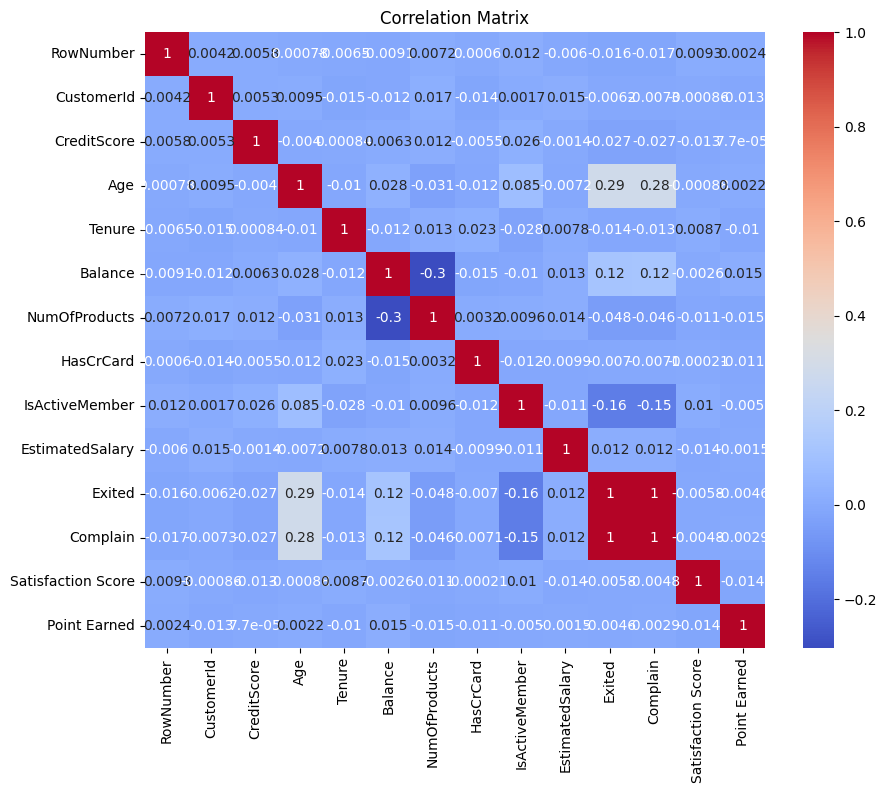

In [44]:
# calculating correlation bwt numeric features using a heatmap
corr = data.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

### Feature Insights and Summary Statistics

        CreditScore        Age       Balance    Tenure  Satisfaction Score
Exited                                                                    
0        651.837855  37.408063  72742.750663  5.032781            3.017960
1        645.414622  44.835623  91109.476006  4.934740            2.997547


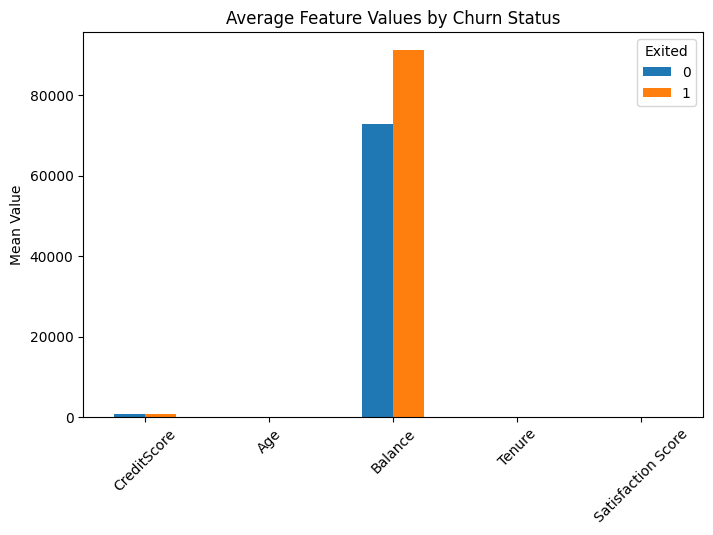

In [45]:
churn_mean = data.groupby('Exited')[['CreditScore', 'Age', 'Balance', 'Tenure', 'Satisfaction Score']].mean()
#Visualize
print(churn_mean)
churn_mean.T.plot(kind='bar', figsize=(8,5))
plt.title('Average Feature Values by Churn Status')
plt.ylabel('Mean Value')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='Geography', ylabel='Exited'>

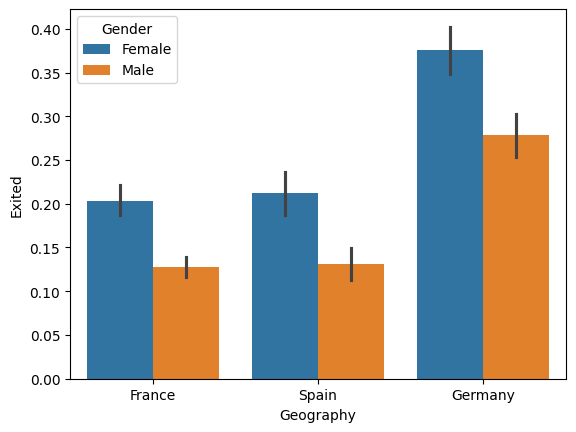

In [46]:
sns.barplot(data=data, x='Geography', y='Exited', hue='Gender')

<Axes: xlabel='TenureGroup', ylabel='Exited'>

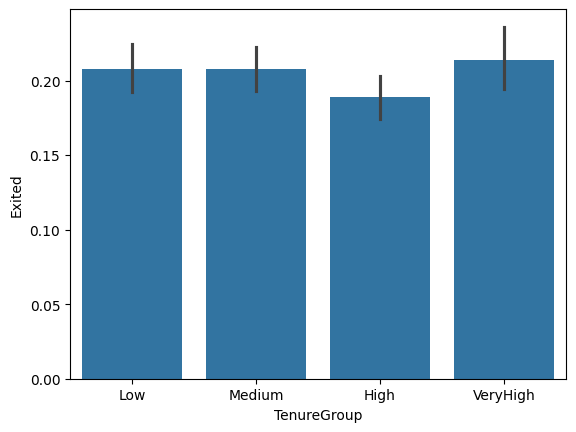

In [47]:
data['TenureGroup'] = pd.cut(data['Tenure'], bins=[0,2,5,8,10], labels=['Low','Medium','High','VeryHigh'])
sns.barplot(data=data, x='TenureGroup', y='Exited')

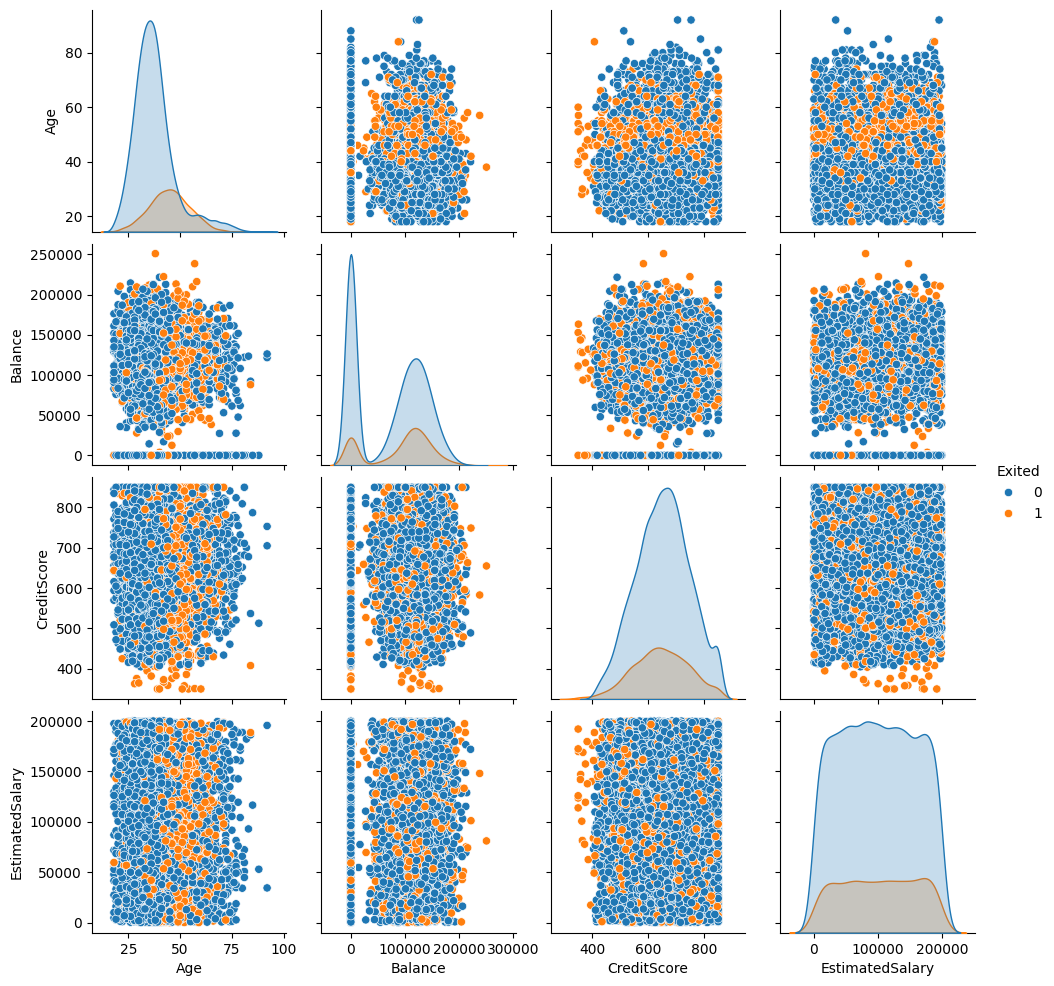

In [48]:
sns.pairplot(data, vars=['Age','Balance','CreditScore','EstimatedSalary'], hue='Exited')

<Axes: xlabel='Exited', ylabel='Balance'>

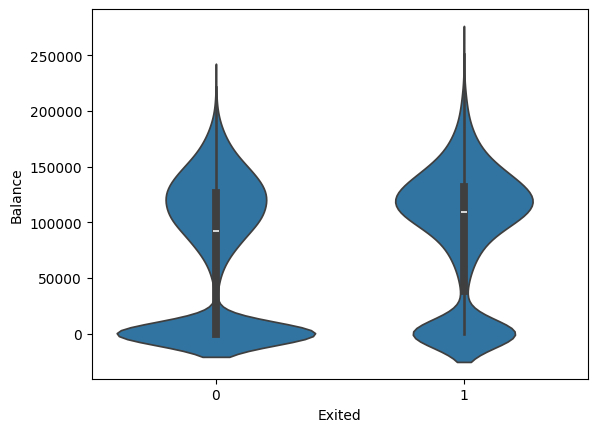

In [49]:
sns.violinplot(data=data, x='Exited', y='Balance')

### EDA Profiling Report

In [50]:
pip install ydata-profiling

This optional profiling package is used to generate a fuller EDA report.

In [51]:
from ydata_profiling import ProfileReport

In [52]:
profile = ProfileReport(
    data,
    title="Comprehensive EDA Report",
    explorative=True,  # Enables correlation, interactions, missing value heatmaps, etc.
    minimal=False      # Ensures full detailed report
)

In [53]:
from pathlib import Path

outputs_dir = Path('../outputs')
outputs_dir.mkdir(parents=True, exist_ok=True)

profile.to_file(str(outputs_dir / 'EDA_Report.html'))  # EDA report is saved as an HTML file

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 19/19 [00:00<00:00, 20.11it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

The profiling report is saved as `../outputs/EDA_Report.html` if the cell is run.

## 5. Feature Selection and Leakage Check

In [54]:
target_col = 'Exited'
customer_ids = data['CustomerId'].copy()

excluded_features = ['RowNumber', 'CustomerId', 'Surname', 'Complain', 'TenureGroup']

excluded_feature_reasons = {
    'RowNumber': 'row identifier',
    'CustomerId': 'customer identifier, preserved separately for later customer-level scoring',
    'Surname': 'not a meaningful predictive feature for this project',
    'Complain': 'potential target leakage because of its very high relationship with Exited',
    'TenureGroup': 'EDA grouping only; raw Tenure remains available for modeling'
}

excluded_feature_reasons

{'RowNumber': 'row identifier',
 'CustomerId': 'customer identifier, preserved separately for later customer-level scoring',
 'Surname': 'not a meaningful predictive feature for this project',
 'Complain': 'potential target leakage because of its very high relationship with Exited',
 'TenureGroup': 'EDA grouping only; raw Tenure remains available for modeling'}

In [55]:
data['Card Type'].unique()

array(['DIAMOND', 'GOLD', 'SILVER', 'PLATINUM'], dtype=object)

In [56]:
data['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [57]:
data.corr(numeric_only=True)['Exited'].sort_values(ascending=False).head(10)

,Exited
Exited,1.000000
Complain,0.995693
Age,0.285296
Balance,0.118577
EstimatedSalary,0.012490
Point Earned,-0.004628
Satisfaction Score,-0.005849
CustomerId,-0.006203
HasCrCard,-0.006976
Tenure,-0.013656


`Complain` is highly correlated with the target, so it is treated as potential leakage and excluded from the modeling feature set. The original dataframe is kept unchanged.

In [58]:
available_exclusions = [col for col in excluded_features if col in data.columns]
model_feature_columns = [col for col in data.columns if col not in available_exclusions + [target_col]]

model_feature_columns

['CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Satisfaction Score',
 'Card Type',
 'Point Earned']

## 6. Data Preparation

In [59]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

In [60]:
X = data[model_feature_columns].copy()
y = data[target_col].copy()

X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,5,GOLD,425


## 7. Train-Test Split and Preprocessing

In [61]:
X_train, X_test, y_train, y_test, customer_id_train, customer_id_test = train_test_split(
    X,
    y,
    customer_ids,
    test_size=0.20,
    random_state=42,
    stratify=y
)

### Feature Types and Preprocessing Setup

In [62]:
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print('Categorical features:', categorical_features)
print('Numerical features:', numerical_features)

Categorical features: ['Geography', 'Gender', 'Card Type']
Numerical features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction Score', 'Point Earned']


In [63]:
numeric_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_pipeline, numerical_features),
        ('categorical', categorical_pipeline, categorical_features)
    ]
)

In [64]:
# Preprocessing is intentionally not fitted here.
# It should be fitted on X_train only inside the modeling pipeline in the next phase.

In [65]:
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('y_train churn rate:', y_train.mean())
print('y_test churn rate:', y_test.mean())

X_train shape: (8000, 13)
X_test shape: (2000, 13)
y_train churn rate: 0.20375
y_test churn rate: 0.204


In [66]:
y.value_counts(normalize=True)

,proportion
Exited,
0,0.7962
1,0.2038


SMOTE is not applied in this phase. The imbalance strategy will be compared separately later.

In [67]:
customer_id_test.head()

,CustomerId
6176,15604146
7072,15775750
877,15800228
6539,15749328
5190,15579548


In [68]:
X_train.dtypes

,0
CreditScore,int64
Geography,object
Gender,object
Age,int64
Tenure,int64
Balance,float64
NumOfProducts,int64
HasCrCard,int64
IsActiveMember,int64
EstimatedSalary,float64


In [69]:
X_train.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned
4791,709,Spain,Male,35,2,0.00,2,1,0,104982.39,2,GOLD,422
8881,744,France,Male,29,1,43504.42,1,1,1,119327.75,1,PLATINUM,607
6166,773,France,Male,64,2,145578.28,1,0,1,186172.85,1,SILVER,630
4473,646,Germany,Female,29,4,105957.44,1,1,0,15470.91,1,PLATINUM,345
854,675,France,Female,57,8,0.00,2,0,1,95463.29,3,SILVER,632


## 8. Model Training and Comparison

### Cross-Validated Model Comparison

This section compares Logistic Regression, Random Forest, and XGBoost using only the training data. The held-out test set is not used for model selection.

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

try:
    from xgboost import XGBClassifier
except ImportError as error:
    raise ImportError(
        'XGBoost is not available in this environment. Install xgboost before running the model comparison.'
    ) from error

In [71]:
non_churn_count = (y_train == 0).sum()
churn_count = (y_train == 1).sum()
scale_pos_weight = non_churn_count / churn_count

print('scale_pos_weight:', scale_pos_weight)

scale_pos_weight: 3.9079754601226995


In [72]:
def make_logistic_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
            ('numerical', StandardScaler(), numerical_features)
        ]
    )


def make_tree_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
            ('numerical', 'passthrough', numerical_features)
        ]
    )

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': make_scorer(recall_score, zero_division=0),
    'F1': make_scorer(f1_score, zero_division=0),
    'ROC-AUC': 'roc_auc',
    'PR-AUC': 'average_precision'
}

In [73]:
model_pipelines = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocessor', make_logistic_preprocessor()),
        ('model', LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=42
        ))
    ]),
    'Random Forest': Pipeline(steps=[
        ('preprocessor', make_tree_preprocessor()),
        ('model', RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]),
    'XGBoost': Pipeline(steps=[
        ('preprocessor', make_tree_preprocessor()),
        ('model', XGBClassifier(
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        ))
    ])
}

In [74]:
model_cv_rows = []
model_fold_metrics = {}

for model_name, pipeline in model_pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1
    )

    fold_scores = pd.DataFrame({
        metric: scores[f'test_{metric}'] for metric in scoring
    })
    model_fold_metrics[model_name] = fold_scores

    result_row = {'Model': model_name}
    for metric in scoring:
        result_row[f'{metric} Mean'] = fold_scores[metric].mean()
        result_row[f'{metric} Std'] = fold_scores[metric].std()

    model_cv_rows.append(result_row)

model_comparison_cv = pd.DataFrame(model_cv_rows)
model_comparison_display = model_comparison_cv[['Model']].copy()
for metric in scoring:
    model_comparison_display[metric] = model_comparison_cv.apply(
        lambda row: f"{row[f'{metric} Mean']:.4f} ± {row[f'{metric} Std']:.4f}",
        axis=1
    )

model_comparison_display

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.7099 ± 0.0069,0.3824 ± 0.0084,0.6896 ± 0.0351,0.4918 ± 0.0140,0.7663 ± 0.0086,0.4535 ± 0.0219
1,Random Forest,0.8575 ± 0.0046,0.7998 ± 0.0256,0.4012 ± 0.0125,0.5343 ± 0.0150,0.8544 ± 0.0086,0.6711 ± 0.0231
2,XGBoost,0.8286 ± 0.0095,0.5768 ± 0.0229,0.5969 ± 0.0288,0.5866 ± 0.0242,0.8308 ± 0.0166,0.6532 ± 0.0303


In [76]:
from pathlib import Path

outputs_dir = Path('../outputs')
outputs_dir.mkdir(parents=True, exist_ok=True)

model_comparison_cv.to_csv(outputs_dir / 'model_comparison_cv.csv', index=False)

Based on cross-validation, Random Forest is the strongest candidate for final evaluation because it has the best churn F1, ROC-AUC, PR-AUC, precision, and accuracy. Logistic Regression has the highest recall, but its much lower precision means it flags many more non-churners as churners. XGBoost has slightly higher recall than Random Forest, but its F1, ROC-AUC, and PR-AUC are lower in this run. This is only a candidate choice; the held-out test set has not been evaluated yet.

## 9. Final Model Evaluation

### Held-Out Test Evaluation

The final candidate is the balanced Random Forest pipeline. The operating threshold is fixed at `0.43`, selected from out-of-fold training analysis before looking at the test set.

In [77]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

In [78]:
final_threshold = 0.43
reference_threshold = 0.50

final_rf_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numerical', 'passthrough', numerical_features)
    ]
)

final_rf_pipeline = Pipeline(steps=[
    ('preprocessor', final_rf_preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

final_rf_pipeline.fit(X_train, y_train)
test_churn_probabilities = final_rf_pipeline.predict_proba(X_test)[:, 1]

In [79]:
test_roc_auc = roc_auc_score(y_test, test_churn_probabilities)
test_pr_auc = average_precision_score(y_test, test_churn_probabilities)


def evaluate_threshold(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()

    return {
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
        'F1': f1_score(y_true, predictions, zero_division=0),
        'True Negatives': int(tn),
        'False Positives': int(fp),
        'False Negatives': int(fn),
        'True Positives': int(tp),
        'Predicted Churn Count': int(predictions.sum())
    }

final_threshold_metrics = evaluate_threshold(y_test, test_churn_probabilities, final_threshold)
reference_threshold_metrics = evaluate_threshold(y_test, test_churn_probabilities, reference_threshold)

final_threshold_metrics

{'Threshold': 0.43,
 'Accuracy': 0.8655,
 'Precision': 0.743859649122807,
 'Recall': 0.5196078431372549,
 'F1': 0.6118326118326118,
 'True Negatives': 1519,
 'False Positives': 73,
 'False Negatives': 196,
 'True Positives': 212,
 'Predicted Churn Count': 285}

In [80]:
final_threshold_comparison = pd.DataFrame([
    reference_threshold_metrics,
    final_threshold_metrics
])[
    ['Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'False Positives', 'False Negatives']
]

final_model_metrics = pd.DataFrame([{
    **final_threshold_metrics,
    'ROC-AUC': test_roc_auc,
    'PR-AUC': test_pr_auc,
    'Actual Churners': int((y_test == 1).sum()),
    'Correctly Identified Churners': int(final_threshold_metrics['True Positives']),
    'Missed Churners': int(final_threshold_metrics['False Negatives'])
}])

print('Test ROC-AUC:', test_roc_auc)
print('Test PR-AUC:', test_pr_auc)
final_threshold_comparison.round(4)

Test ROC-AUC: 0.8662422098236279
Test PR-AUC: 0.7015174928678605


,Threshold,Accuracy,Precision,Recall,F1,False Positives,False Negatives
0,0.50,0.8685,0.8404,0.4387,0.5765,34,229
1,0.43,0.8655,0.7439,0.5196,0.6118,73,196


In [81]:
test_customer_predictions = pd.DataFrame({
    'CustomerId': customer_id_test.reset_index(drop=True),
    'ActualExited': y_test.reset_index(drop=True),
    'ChurnProbability': test_churn_probabilities,
    'PredictedChurn': (test_churn_probabilities >= final_threshold).astype(int)
})

test_customer_predictions.head()

,CustomerId,ActualExited,ChurnProbability,PredictedChurn
0,15604146,0,0.220000,0
1,15775750,0,0.080000,0
2,15800228,0,0.160000,0
3,15749328,1,0.160000,0
4,15579548,0,0.056667,0


In [83]:
from pathlib import Path

outputs_dir = Path('../outputs')
processed_dir = Path('../data/processed')
outputs_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

final_model_metrics.to_csv(outputs_dir / 'final_model_metrics.csv', index=False)
final_threshold_comparison.to_csv(outputs_dir / 'final_threshold_comparison.csv', index=False)
test_customer_predictions.to_csv(processed_dir / 'test_customer_predictions.csv', index=False)

print('Saved final metrics to ../outputs/final_model_metrics.csv')
print('Saved threshold comparison to ../outputs/final_threshold_comparison.csv')
print('Saved customer predictions to ../data/processed/test_customer_predictions.csv')

At the fixed threshold `0.43`, the model identifies more churners than the default `0.50` threshold but also produces more false positives. The threshold was not adjusted after looking at test performance.

## 10. Churn Probability and Threshold Analysis

No churn probability or threshold changes were added in this organization phase.

### Training-Only Threshold Analysis

This section uses out-of-fold churn probabilities from the balanced Random Forest candidate. The held-out test set is not used.

In [84]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

In [85]:
threshold_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_threshold_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numerical', 'passthrough', numerical_features)
    ]
)

rf_threshold_pipeline = Pipeline(steps=[
    ('preprocessor', rf_threshold_preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

In [86]:
oof_churn_probabilities = cross_val_predict(
    rf_threshold_pipeline,
    X_train,
    y_train,
    cv=threshold_cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

print('Out-of-fold probability count:', len(oof_churn_probabilities))

Out-of-fold probability count: 8000


In [87]:
threshold_rows = []
thresholds = np.arange(20, 81) / 100

for threshold in thresholds:
    y_pred_threshold = (oof_churn_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred_threshold, labels=[0, 1]).ravel()

    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_train, y_pred_threshold, zero_division=0),
        'Recall': recall_score(y_train, y_pred_threshold, zero_division=0),
        'F1': f1_score(y_train, y_pred_threshold, zero_division=0),
        'Accuracy': accuracy_score(y_train, y_pred_threshold),
        'Predicted Churn Count': int(y_pred_threshold.sum()),
        'False Positives': int(fp),
        'False Negatives': int(fn)
    })

threshold_analysis_cv = pd.DataFrame(threshold_rows)
threshold_analysis_cv.head()

,Threshold,Precision,Recall,F1,Accuracy,Predicted Churn Count,False Positives,False Negatives
0,0.20,0.466095,0.767485,0.579972,0.773500,2684,1433,379
1,0.21,0.481176,0.752761,0.587081,0.784250,2550,1323,403
2,0.22,0.494451,0.738037,0.592173,0.792875,2433,1230,427
3,0.23,0.509702,0.725153,0.598633,0.801875,2319,1137,448
4,0.24,0.522563,0.710429,0.602184,0.808750,2216,1058,472


In [88]:
default_threshold_metrics = threshold_analysis_cv.loc[
    threshold_analysis_cv['Threshold'].eq(0.50)
].iloc[0]

best_f1_threshold_metrics = threshold_analysis_cv.loc[
    threshold_analysis_cv['F1'].idxmax()
]

precision_requirement = 0.50
thresholds_with_required_precision = threshold_analysis_cv[
    threshold_analysis_cv['Precision'] >= precision_requirement
]

if thresholds_with_required_precision.empty:
    highest_recall_precision_50_metrics = None
    print('No threshold has precision >= 0.50')
else:
    highest_recall_precision_50_metrics = thresholds_with_required_precision.loc[
        thresholds_with_required_precision['Recall'].idxmax()
    ]

threshold_summary = pd.DataFrame([
    default_threshold_metrics,
    best_f1_threshold_metrics,
    highest_recall_precision_50_metrics
], index=[
    'Default threshold 0.50',
    'Highest F1',
    'Highest recall with precision >= 0.50'
]).dropna(how='all')

threshold_summary.round(4)

,Threshold,Precision,Recall,F1,Accuracy,Predicted Churn Count,False Positives,False Negatives
Default threshold 0.50,0.50,0.7971,0.4025,0.5349,0.8574,823.0,167.0,974.0
Highest F1,0.31,0.6135,0.6282,0.6208,0.8436,1669.0,645.0,606.0
Highest recall with precision >= 0.50,0.23,0.5097,0.7252,0.5986,0.8019,2319.0,1137.0,448.0


In [90]:
from pathlib import Path

outputs_dir = Path('../outputs')
outputs_dir.mkdir(parents=True, exist_ok=True)

threshold_analysis_cv.to_csv(outputs_dir / 'threshold_analysis_cv.csv', index=False)

Lower thresholds catch more churners but create more false positives. Higher thresholds reduce false positives but miss more churners. No final threshold is chosen here because the held-out test set has not been evaluated yet.

## 11. Customer Risk Segmentation

No customer risk segmentation was added in this organization phase.

### Held-Out Customer Risk Scores

This section uses the saved held-out test predictions only. `0.43` is the fixed operating threshold from the training-only threshold analysis, while `0.25` is a practical watchlist boundary.


In [91]:
import numpy as np

risk_threshold = 0.43
watchlist_threshold = 0.25

if 'test_customer_predictions' not in globals():
    test_customer_predictions = pd.read_csv('../data/processed/test_customer_predictions.csv')

risk_attribute_columns = [
    'CustomerId',
    'CreditScore',
    'Geography',
    'Gender',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'HasCrCard',
    'IsActiveMember',
    'EstimatedSalary',
    'Satisfaction Score',
    'Card Type',
    'Point Earned'
]

customer_risk_scores = test_customer_predictions.merge(
    data[risk_attribute_columns],
    on='CustomerId',
    how='left',
    validate='one_to_one'
)

if customer_risk_scores[risk_attribute_columns].isnull().any().any():
    raise ValueError('Some held-out customers could not be matched back to the original attributes.')

customer_risk_scores = customer_risk_scores[
    risk_attribute_columns + ['ActualExited', 'ChurnProbability', 'PredictedChurn']
]

customer_risk_scores.head()

,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned,ActualExited,ChurnProbability,PredictedChurn
0,15604146,608,Germany,Female,38,8,103653.51,2,1,1,137079.86,3,SILVER,843,0,0.220000,0
1,15775750,686,France,Male,37,9,134560.62,1,1,0,27596.39,1,DIAMOND,617,0,0.080000,0
2,15800228,652,Spain,Female,42,4,0.00,2,1,1,38152.01,5,GOLD,230,0,0.160000,0
3,15749328,697,France,Female,45,1,0.00,2,1,0,46807.62,3,PLATINUM,559,1,0.160000,0
4,15579548,735,Spain,Male,36,5,0.00,2,1,0,105152.17,3,PLATINUM,259,0,0.056667,0


In [92]:
customer_risk_scores['RiskSegment'] = np.select(
    [
        customer_risk_scores['ChurnProbability'] >= risk_threshold,
        customer_risk_scores['ChurnProbability'] >= watchlist_threshold
    ],
    ['High', 'Medium'],
    default='Low'
)

training_balance_75th_percentile = X_train['Balance'].quantile(0.75)
customer_risk_scores['HighValueCustomer'] = (
    customer_risk_scores['Balance'] >= training_balance_75th_percentile
).astype(int)
customer_risk_scores['InactiveFlag'] = (customer_risk_scores['IsActiveMember'] == 0).astype(int)

print('75th percentile training balance threshold:', training_balance_75th_percentile)

75th percentile training balance threshold: 127665.115


In [93]:
segment_order = ['Low', 'Medium', 'High']
customer_risk_scores['RiskSegment'] = pd.Categorical(
    customer_risk_scores['RiskSegment'],
    categories=segment_order,
    ordered=True
)

risk_segment_summary = customer_risk_scores.groupby('RiskSegment', observed=False).agg(
    CustomerCount=('CustomerId', 'count'),
    AverageChurnProbability=('ChurnProbability', 'mean'),
    ActualChurnCount=('ActualExited', 'sum'),
    ActualChurnRate=('ActualExited', 'mean'),
    AverageBalance=('Balance', 'mean'),
    ActiveMemberPercentage=('IsActiveMember', 'mean'),
    AverageSatisfactionScore=('Satisfaction Score', 'mean')
).reset_index()

risk_segment_summary['PercentageOfTestCustomers'] = (
    risk_segment_summary['CustomerCount'] / len(customer_risk_scores)
)

risk_segment_summary = risk_segment_summary[
    [
        'RiskSegment',
        'CustomerCount',
        'PercentageOfTestCustomers',
        'AverageChurnProbability',
        'ActualChurnCount',
        'ActualChurnRate',
        'AverageBalance',
        'ActiveMemberPercentage',
        'AverageSatisfactionScore'
    ]
]

risk_segment_summary.round(4)

,RiskSegment,CustomerCount,PercentageOfTestCustomers,AverageChurnProbability,ActualChurnCount,ActualChurnRate,AverageBalance,ActiveMemberPercentage,AverageSatisfactionScore
0,Low,1437,0.7185,0.0978,104,0.0724,69684.6923,0.5644,3.0355
1,Medium,278,0.1390,0.3286,92,0.3309,95631.3557,0.4784,3.0863
2,High,285,0.1425,0.6178,212,0.7439,93259.9142,0.2596,2.9123


### High-Risk Segment Profile

The high-risk profile summarizes observed characteristics in the held-out customers classified at or above the fixed threshold. These are descriptive patterns, not causal claims.


In [94]:
high_risk_customers = customer_risk_scores[customer_risk_scores['RiskSegment'] == 'High'].copy()

high_risk_profile = pd.DataFrame([{
    'HighRiskCustomerCount': len(high_risk_customers),
    'ActualChurnCount': int(high_risk_customers['ActualExited'].sum()),
    'ActualNonChurnCount': int((high_risk_customers['ActualExited'] == 0).sum()),
    'ActualChurnRate': high_risk_customers['ActualExited'].mean(),
    'InactiveMemberPercentage': high_risk_customers['InactiveFlag'].mean(),
    'AverageBalance': high_risk_customers['Balance'].mean(),
    'AverageNumOfProducts': high_risk_customers['NumOfProducts'].mean(),
    'AverageSatisfactionScore': high_risk_customers['Satisfaction Score'].mean(),
    'HighValueCustomerCount': int(high_risk_customers['HighValueCustomer'].sum())
}])

high_risk_profile.round(4)

,HighRiskCustomerCount,ActualChurnCount,ActualNonChurnCount,ActualChurnRate,InactiveMemberPercentage,AverageBalance,AverageNumOfProducts,AverageSatisfactionScore,HighValueCustomerCount
0,285,212,73,0.7439,0.7404,93259.9142,1.5754,2.9123,84


In [95]:
high_risk_geography_distribution = (
    high_risk_customers['Geography']
    .value_counts()
    .rename_axis('Geography')
    .reset_index(name='CustomerCount')
)
high_risk_geography_distribution['PercentageOfHighRisk'] = (
    high_risk_geography_distribution['CustomerCount'] / len(high_risk_customers)
)

high_risk_geography_distribution.round(4)

,Geography,CustomerCount,PercentageOfHighRisk
0,Germany,138,0.4842
1,France,96,0.3368
2,Spain,51,0.1789


In [97]:
from pathlib import Path

processed_dir = Path('../data/processed')
outputs_dir = Path('../outputs')
processed_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

customer_risk_scores.to_csv(processed_dir / 'customer_risk_scores.csv', index=False)
risk_segment_summary.to_csv(outputs_dir / 'risk_segment_summary.csv', index=False)

print('Saved customer risk scores to ../data/processed/customer_risk_scores.csv')
print('Saved risk segment summary to ../outputs/risk_segment_summary.csv')

This segmentation uses only held-out test customers. Retention actions are left for the next phase.

## 12. Retention Recommendations


### Retention Prioritization Logic

This framework uses the held-out risk scores from Section 11. `ActualExited` is kept only for post-hoc evaluation and is not used to assign priority, action, or reason.


In [98]:
if 'customer_risk_scores' not in globals():
    customer_risk_scores = pd.read_csv('../data/processed/customer_risk_scores.csv')

customer_retention_priorities = customer_risk_scores.copy()

priority_conditions = [
    (customer_retention_priorities['RiskSegment'] == 'High') & (customer_retention_priorities['HighValueCustomer'] == 1),
    (customer_retention_priorities['RiskSegment'] == 'High') & (customer_retention_priorities['HighValueCustomer'] == 0) & (customer_retention_priorities['InactiveFlag'] == 1),
    customer_retention_priorities['RiskSegment'] == 'High',
    customer_retention_priorities['RiskSegment'] == 'Medium'
]

priority_labels = [
    'Priority 1',
    'Priority 2',
    'Priority 3',
    'Watchlist'
]

customer_retention_priorities['RetentionPriority'] = np.select(
    priority_conditions,
    priority_labels,
    default='Routine'
)

action_map = {
    'Priority 1': 'Priority retention review / relationship-manager outreach',
    'Priority 2': 'Reactivation outreach',
    'Priority 3': 'Targeted retention outreach',
    'Watchlist': 'Monitor and targeted engagement',
    'Routine': 'Standard customer servicing'
}

reason_map = {
    'Priority 1': 'High churn risk and high balance',
    'Priority 2': 'High churn risk and inactive membership',
    'Priority 3': 'High churn probability',
    'Watchlist': 'Moderate churn probability',
    'Routine': 'Low churn probability'
}

customer_retention_priorities['RecommendedAction'] = customer_retention_priorities['RetentionPriority'].map(action_map)
customer_retention_priorities['ActionReason'] = customer_retention_priorities['RetentionPriority'].map(reason_map)

customer_retention_priorities.head()

,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,...,Point Earned,ActualExited,ChurnProbability,PredictedChurn,RiskSegment,HighValueCustomer,InactiveFlag,RetentionPriority,RecommendedAction,ActionReason
0,15604146,608,Germany,Female,38,8,103653.51,2,1,1,...,843,0,0.220000,0,Low,0,0,Routine,Standard customer servicing,Low churn probability
1,15775750,686,France,Male,37,9,134560.62,1,1,0,...,617,0,0.080000,0,Low,1,1,Routine,Standard customer servicing,Low churn probability
2,15800228,652,Spain,Female,42,4,0.00,2,1,1,...,230,0,0.160000,0,Low,0,0,Routine,Standard customer servicing,Low churn probability
3,15749328,697,France,Female,45,1,0.00,2,1,0,...,559,1,0.160000,0,Low,0,1,Routine,Standard customer servicing,Low churn probability
4,15579548,735,Spain,Male,36,5,0.00,2,1,0,...,259,0,0.056667,0,Low,0,1,Routine,Standard customer servicing,Low churn probability


### Priority Summary

The actual churn rate is shown as post-hoc evaluation only. It was not used to create the priority groups or recommended actions.


In [99]:
priority_order = ['Priority 1', 'Priority 2', 'Priority 3', 'Watchlist', 'Routine']
customer_retention_priorities['RetentionPriority'] = pd.Categorical(
    customer_retention_priorities['RetentionPriority'],
    categories=priority_order,
    ordered=True
)

retention_priority_summary = customer_retention_priorities.groupby('RetentionPriority', observed=False).agg(
    CustomerCount=('CustomerId', 'count'),
    AverageChurnProbability=('ChurnProbability', 'mean'),
    AverageBalance=('Balance', 'mean'),
    InactiveMemberPercentage=('InactiveFlag', 'mean'),
    HighValueCustomerPercentage=('HighValueCustomer', 'mean'),
    ActualChurnRatePostHoc=('ActualExited', 'mean')
).reset_index()

retention_priority_summary['PercentageOfScoredCustomers'] = (
    retention_priority_summary['CustomerCount'] / len(customer_retention_priorities)
)

retention_priority_summary = retention_priority_summary[
    [
        'RetentionPriority',
        'CustomerCount',
        'PercentageOfScoredCustomers',
        'AverageChurnProbability',
        'AverageBalance',
        'InactiveMemberPercentage',
        'HighValueCustomerPercentage',
        'ActualChurnRatePostHoc'
    ]
]

retention_priority_summary.round(4)

,RetentionPriority,CustomerCount,PercentageOfScoredCustomers,AverageChurnProbability,AverageBalance,InactiveMemberPercentage,HighValueCustomerPercentage,ActualChurnRatePostHoc
0,Priority 1,84,0.0420,0.6248,148912.7861,0.7143,1.0000,0.7500
1,Priority 2,151,0.0755,0.6301,69116.8638,1.0000,0.0000,0.7616
2,Priority 3,50,0.0250,0.5691,72675.1016,0.0000,0.0000,0.6800
3,Watchlist,278,0.1390,0.3286,95631.3557,0.5216,0.3525,0.3309
4,Routine,1437,0.7185,0.0978,69684.6923,0.4356,0.2185,0.0724


In [100]:
priority_churn_capture = customer_retention_priorities.groupby('RetentionPriority', observed=False).agg(
    CustomerCount=('CustomerId', 'count'),
    ActualChurnCount=('ActualExited', 'sum'),
    ActualChurnRatePostHoc=('ActualExited', 'mean')
).reset_index()

priority_1_2_mask = customer_retention_priorities['RetentionPriority'].isin(['Priority 1', 'Priority 2'])
priority_1_2_churners = int(customer_retention_priorities.loc[priority_1_2_mask, 'ActualExited'].sum())
total_test_churners = int(customer_retention_priorities['ActualExited'].sum())
priority_1_2_churn_capture_rate = priority_1_2_churners / total_test_churners

print('Actual churners captured in Priority 1 + Priority 2:', priority_1_2_churners)
print('Percentage of all test churners captured:', priority_1_2_churn_capture_rate)
priority_churn_capture.round(4)

Actual churners captured in Priority 1 + Priority 2: 178
Percentage of all test churners captured: 0.4362745098039216


,RetentionPriority,CustomerCount,ActualChurnCount,ActualChurnRatePostHoc
0,Priority 1,84,63,0.7500
1,Priority 2,151,115,0.7616
2,Priority 3,50,34,0.6800
3,Watchlist,278,92,0.3309
4,Routine,1437,104,0.0724


In [101]:
from pathlib import Path

processed_dir = Path('../data/processed')
outputs_dir = Path('../outputs')
processed_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

customer_retention_priorities.to_csv(processed_dir / 'customer_retention_priorities.csv', index=False)
retention_priority_summary.to_csv(outputs_dir / 'retention_priority_summary.csv', index=False)

print('Saved customer retention priorities to ../data/processed/customer_retention_priorities.csv')
print('Saved retention priority summary to ../outputs/retention_priority_summary.csv')

High-risk customers are prioritized because they have the highest modeled churn probabilities in the held-out scoring file. High-value high-risk customers are handled first because their balances are at or above the training-set 75th percentile. Inactive high-risk customers receive reactivation outreach because inactivity is a known customer attribute before churn occurs. These recommendations are suggested interventions based on modeled risk and customer attributes, not proven causal treatments.


## 13. Feature Importance

In [103]:
preprocessor = final_rf_pipeline.named_steps['preprocessor']
rf_model = final_rf_pipeline.named_steps['model']

categorical_encoder = preprocessor.named_transformers_['categorical']
categorical_feature_names = categorical_encoder.get_feature_names_out(
    categorical_features
)

feature_names = list(categorical_feature_names) + list(numerical_features)
importances = rf_model.feature_importances_

if len(feature_names) != len(importances):
    raise ValueError(
        "Feature name count does not match feature importance count."
    )

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

top_15_feature_importance = feature_importance_df.head(15)

top_15_feature_importance

,Feature,Importance
0,Age,0.220650
1,NumOfProducts,0.115184
2,Balance,0.107675
3,EstimatedSalary,0.098995
4,Point Earned,0.096451
5,CreditScore,0.095988
6,Tenure,0.060899
7,Satisfaction Score,0.041020
8,IsActiveMember,0.032686
9,Geography_Germany,0.024609


In [106]:
from pathlib import Path

outputs_dir = Path('../outputs')
outputs_dir.mkdir(parents=True, exist_ok=True)

feature_importance_df.to_csv(outputs_dir / 'feature_importance.csv', index=False)

print('Feature importance saved to ../outputs/feature_importance.csv')

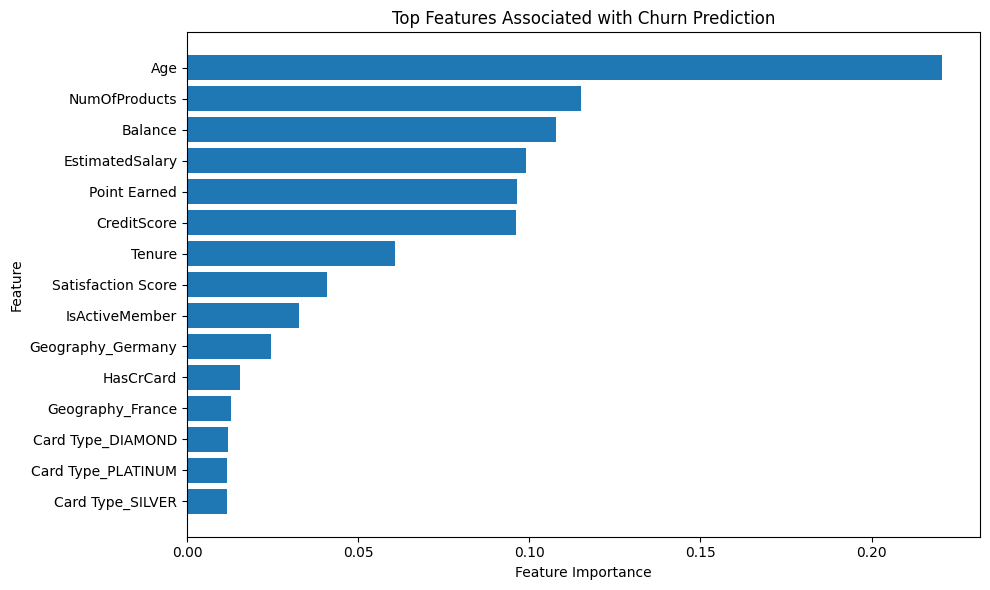

In [107]:
import matplotlib.pyplot as plt

plot_data = top_15_feature_importance.sort_values(
    'Importance',
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data['Feature'],
    plot_data['Importance']
)

plt.title('Top Features Associated with Churn Prediction')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

The final Random Forest relied most heavily on Age, followed by NumOfProducts, Balance, EstimatedSalary, Point Earned, and CreditScore. Features such as customer activity status and geography also contributed to the model, but to a smaller extent. These importance scores show which variables were useful to the model for prediction and should not be interpreted as causal drivers of churn.

## 14. Business Conclusions


*   The dataset contains 10,000 customers, with an overall observed churn rate of 20.38%.
*   Churn was higher among some customer groups. For example, Germany showed a 32.44% churn rate, while inactive customers had a churn rate of 26.87% compared with 14.27% for active customers.

*   The 50–59 age group had the highest observed churn rate among the defined age bands at 56.04%.

*  The final balanced Random Forest achieved a ROC-AUC of 0.8640 and PR-AUC of 0.6869 on the held-out test set.

*   Using the pre-selected probability threshold of 0.43, the model achieved 68.38% recall, correctly identifying 279 of 408 actual churners in the test set.

*   The model classified 492 customers as High Risk, with an observed churn rate of 56.71% in this group.

*   The retention framework placed 370 customers in Priority 1 and Priority 2, and these groups contained 226 of the 408 actual churners in post-hoc evaluation.
*   The project shows how descriptive analytics, predictive modeling, and customer prioritization can be combined to support more focused retention efforts. The suggested retention actions are based on modeled risk and customer characteristics and should not be treated as proven causal treatments.



